# Stocks, flows and feedback in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/02-stocks-flows.ipynb)

This notebook is the Python companion to three LoopBricks molecules: [Bathtub](https://waelrash1.github.io/loopbricks/#/m/bathtub), [Close Gap](https://waelrash1.github.io/loopbricks/#/m/closegap) and [Stock Management](https://waelrash1.github.io/loopbricks/#/m/stockmgmt). You will

1. write a stock and its flows in ten lines of plain Python,
2. run the same model with the `loopbricks` package and see that it gives the same numbers,
3. explore goal seeking and the time constant,
4. find out why ignoring the supply line makes a stock overshoot,
5. write a model of your own.

The `loopbricks` package runs the same model files as the app, so every number here matches what you see there.

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. A stock is what the flows leave behind

A stock changes only through its flows. Over a short time step `dt`, the stock grows by `dt × (inflow − outflow)`. Repeat that step and you have simulated a model: this is **Euler's method**, and it is all a system dynamics simulator does underneath.

Here is a bathtub that holds 50 units, with 14 flowing in and 6 flowing out each year. The outflow stops when the tub is empty, and the level can never go below zero.

Level after 60 years: 530.0


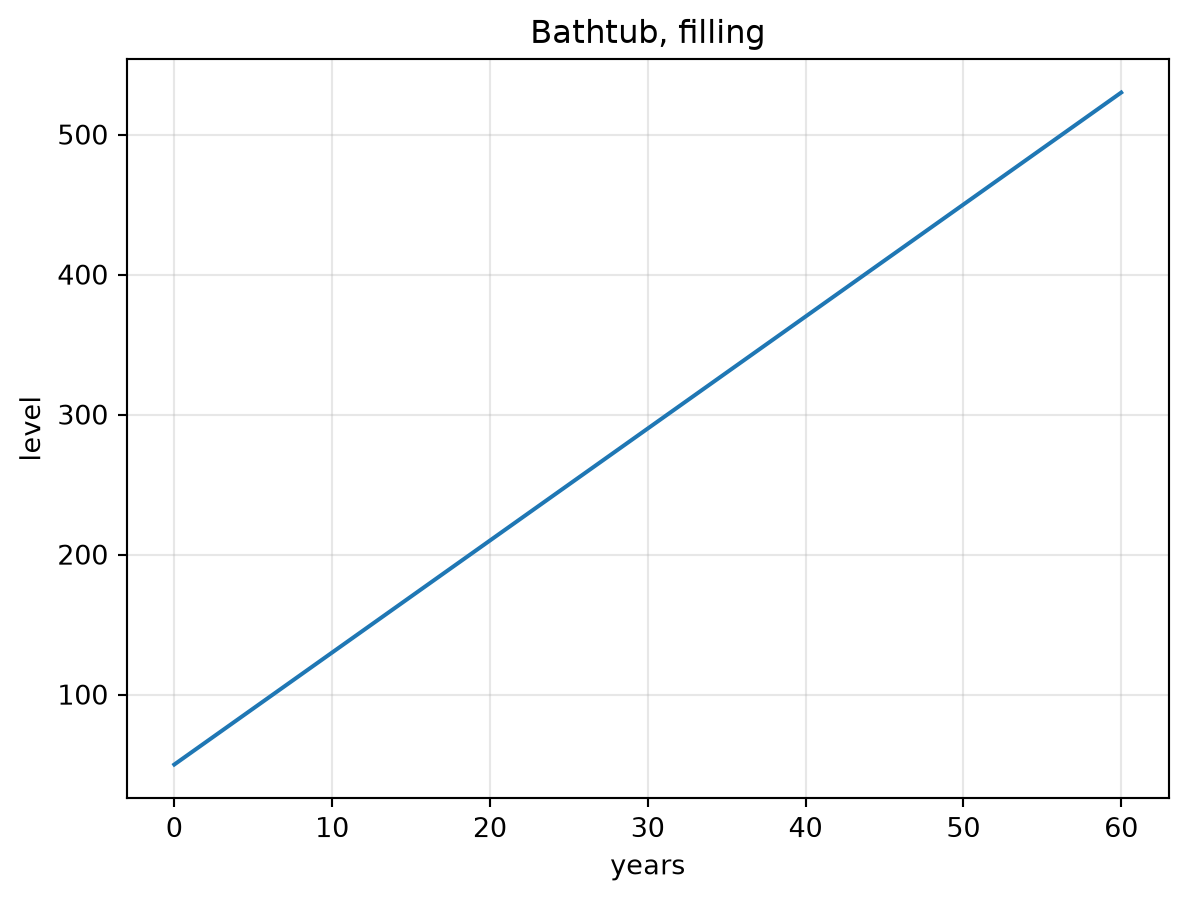

In [2]:
dt, T = 0.1, 60                      # time step and length of the run, in years
level, inflow, outflow = 50.0, 14.0, 6.0

times, levels = [0.0], [level]
for i in range(round(T / dt)):
    out = outflow if level > 0 else 0.0  # nothing drains from an empty tub
    level = max(0.0, level + dt * (inflow - out))
    times.append(round((i + 1) * dt, 10))
    levels.append(level)

plt.plot(times, levels)
plt.xlabel("years"); plt.ylabel("level"); plt.title("Bathtub, filling"); plt.grid(alpha=0.3)
print(f"Level after {T} years: {levels[-1]:.1f}")

The net flow is a constant 8 a year, so the level rises in a straight line: 50 + 8 × 60 = 530. A constant net flow gives a straight line; a net flow that changes gives a curve. That is the first rule of reading stocks and flows.

Now the same model from the package. `lb.molecule("bathtub")` loads the model file the app uses; `run()` returns a pandas DataFrame indexed by time.

In [3]:
tub = lb.molecule("bathtub")
print(tub.equations())
df = tub.run(preset="Filling")
diff = max(abs(a - b) for a, b in zip(df["Level"], levels))
print(f"\nLargest difference from our own loop: {diff:.1e}")

Bathtub

Stocks:
  Level = INTEG(Filling − Draining, 50)

Flows:
  Filling = Inflow
  Draining = IF(Level > 0, Outflow, 0)

Variables:
  Inflow = 10
  Outflow = 8

Largest difference from our own loop: 0.0e+00


The difference is zero: the package does exactly what our loop does, in the same order.

**Try it.** With the *Draining* preset (inflow 3, outflow 12), when is the tub empty? Work it out first, then check with `tub.run(preset="Draining")`.

<details><summary>Show a worked answer</summary>

The net flow is 3 − 12 = −9 a year, so 50 units last 50 / 9 ≈ 5.6 years. The run shows the level reaching zero between 5.5 and 5.6 years, and staying there, because the outflow stops when the tub is empty. After that, the 3 a year flowing in drains straight out again.
</details>

In [4]:
dr = tub.run(preset="Draining")
print("First time the tub is empty:", dr.index[dr["Level"] <= 0][0], "years")

First time the tub is empty: 5.6 years


## 2. Goal seeking and the time constant

In **Close Gap**, the flow is the gap between a goal and the stock, divided by an adjustment time: `Adjusting = (Goal − Actual) / Adjustment_time`. The bigger the gap, the faster the stock moves, so it slows as it gets close. That is a balancing loop, and it produces exponential approach to the goal.

Keyword arguments to `run()` change any constant, by name.

After one adjustment time (week 5): 45.4, so 64% of the gap of 40 is closed


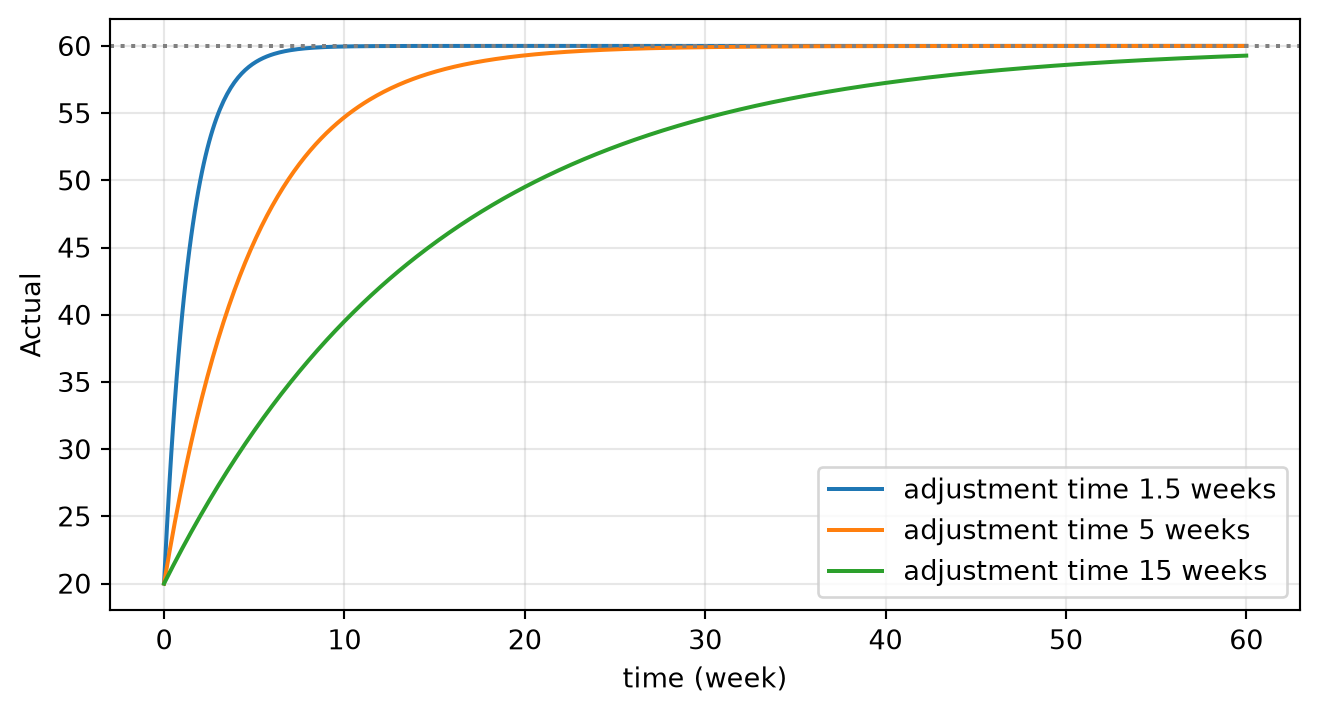

In [5]:
gap = lb.molecule("closegap")
fig, ax = plt.subplots(figsize=(8, 4))
for at in (1.5, 5, 15):
    gap.run(adjustment_time=at)["Actual"].plot(ax=ax, label=f"adjustment time {at} weeks")
ax.axhline(60, ls=":", c="grey"); ax.set_ylabel("Actual"); ax.legend(); ax.grid(alpha=0.3)

run = gap.run(adjustment_time=5)
print(f"After one adjustment time (week 5): {run.loc[5.0, 'Actual']:.1f}, "
      f"so {100 * (run.loc[5.0, 'Actual'] - 20) / 40:.0f}% of the gap of 40 is closed")

After one adjustment time, about two thirds of the gap is closed, whatever the adjustment time is. That makes the adjustment time a **time constant**: it sets the speed of the whole response. (The exact answer is 1 − e⁻¹ = 63.2%. Euler with `dt = 0.1` closes slightly more, 63.6%, because each step uses the gap at the start of the step.)

**Try it.** About how many adjustment times does it take to close 95% of the gap?

<details><summary>Show a worked answer</summary>

About three. Each adjustment time leaves e⁻¹ ≈ 37% of the remaining gap, and 0.37³ ≈ 0.05, so 95% is closed after three adjustment times: about week 15 when the adjustment time is 5. The cell below finds the week in the run.
</details>

In [6]:
print("95% of the gap is closed by week", run.index[run["Actual"] >= 20 + 0.95 * 40][0])

95% of the gap is closed by week 14.9


## 3. Why ignoring the supply line makes a stock overshoot

**Stock Management** orders goods to keep inventory at a target, but goods take an acquisition delay to arrive. Orders already placed and not yet received sit in the **supply line**. A good ordering rule counts them; the `Supply line weight` says how much of the gap in the supply line the decision maker takes into account (1 is all of it, 0 is none).

weight 1: inventory peaks at 100.0 in week 60, ends at 100.0
weight 0.5: inventory peaks at 101.7 in week 22, ends at 100.0
weight 0: inventory peaks at 110.2 in week 17, ends at 100.0


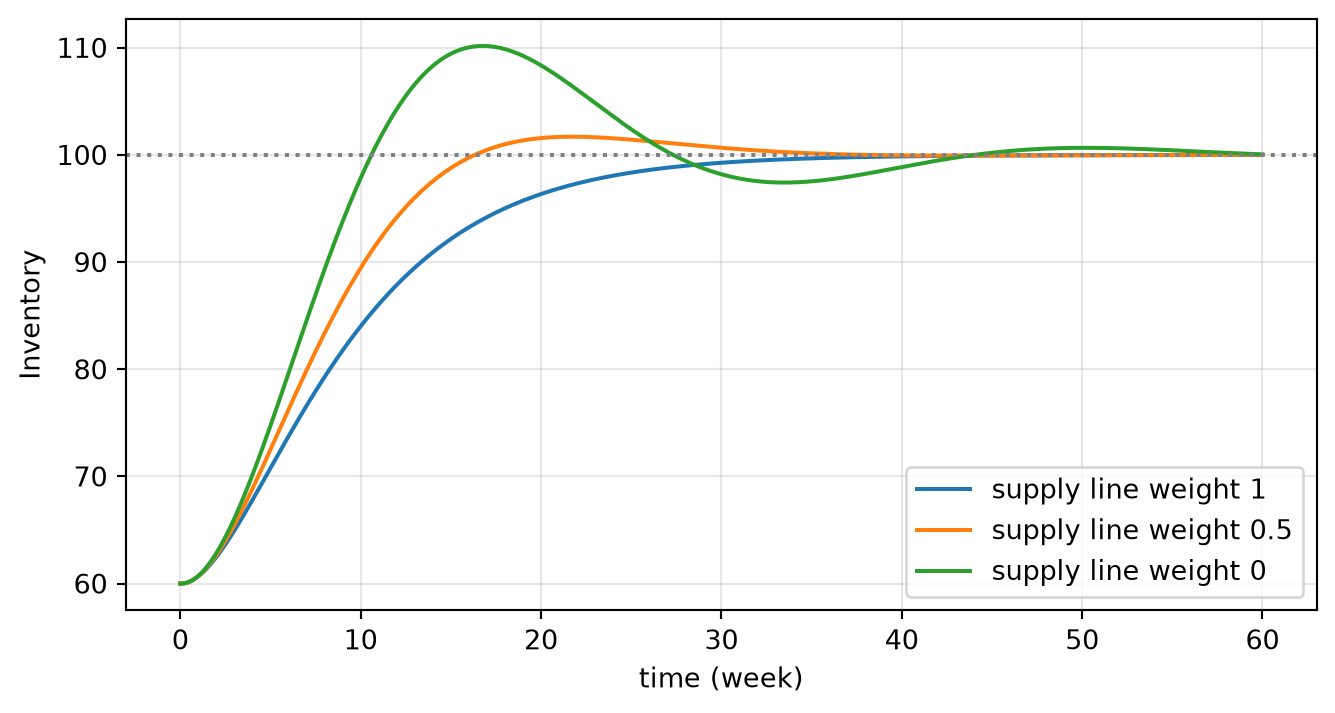

In [7]:
sm = lb.molecule("stockmgmt")
fig, ax = plt.subplots(figsize=(8, 4))
for w in (1, 0.5, 0):
    sm.run(supply_line_weight=w)["Inventory"].plot(ax=ax, label=f"supply line weight {w}")
ax.axhline(100, ls=":", c="grey"); ax.set_ylabel("Inventory"); ax.legend(); ax.grid(alpha=0.3)

for w in (1, 0.5, 0):
    inv = sm.run(supply_line_weight=w)["Inventory"]
    print(f"weight {w}: inventory peaks at {inv.max():.1f} in week {inv.idxmax():.0f}, ends at {inv.iloc[-1]:.1f}")

With full weight, inventory rises smoothly to its target of 100. Count less of the supply line and the order rule keeps ordering for goods that are already on their way, so inventory **overshoots** and then swings back. All three settle at 100 in the end: ignoring the pipeline does not change where the system goes, only how violently it gets there.

This is the structure behind the bullwhip effect in supply chains and the beer game. Try it yourself in the [beer game](https://waelrash1.github.io/loopbricks/#/learn/games/beer).

**Try it.** Use the *Long lead time* preset (a 12-week delay). How much supply line weight is enough to stop inventory overshooting by more than 2%?

<details><summary>Show a worked answer</summary>

Run a sweep over the weight and look at the peak (the next cell). With a 12-week delay the overshoot is large at weight 0 and shrinks as the weight rises; a weight of about 0.5 or more keeps the peak within 2% of the target. Longer delays need more attention to the supply line, because more of the stock is in transit at any time.
</details>

In [8]:
for w in (0, 0.25, 0.5, 0.75, 1):
    inv = sm.run(preset="Long lead time", supply_line_weight=w)["Inventory"]
    print(f"weight {w:<4}: peak {inv.max():6.1f}")

weight 0   : peak  120.1
weight 0.25: peak  108.0
weight 0.5 : peak  101.9
weight 0.75: peak  100.0
weight 1   : peak   99.4


## 4. Your own model

A model is just stocks, flows and variables with equations. Write one as a Python dictionary in the same format the app's model builder uses, and run it. Here is a population with births and deaths as fractions of the population. Change it: add a carrying capacity so that births fall as the population grows, and you have S-shaped growth.

In the app's [model builder](https://waelrash1.github.io/loopbricks/#/learn/build) you can draw a model and use **Export Python notebook** (or *Export JSON*, then `lb.Model.from_file("model.json")`) to continue here.

Population after 100 years: 7,352 (net growth 2% a year doubles it about every 35 years)


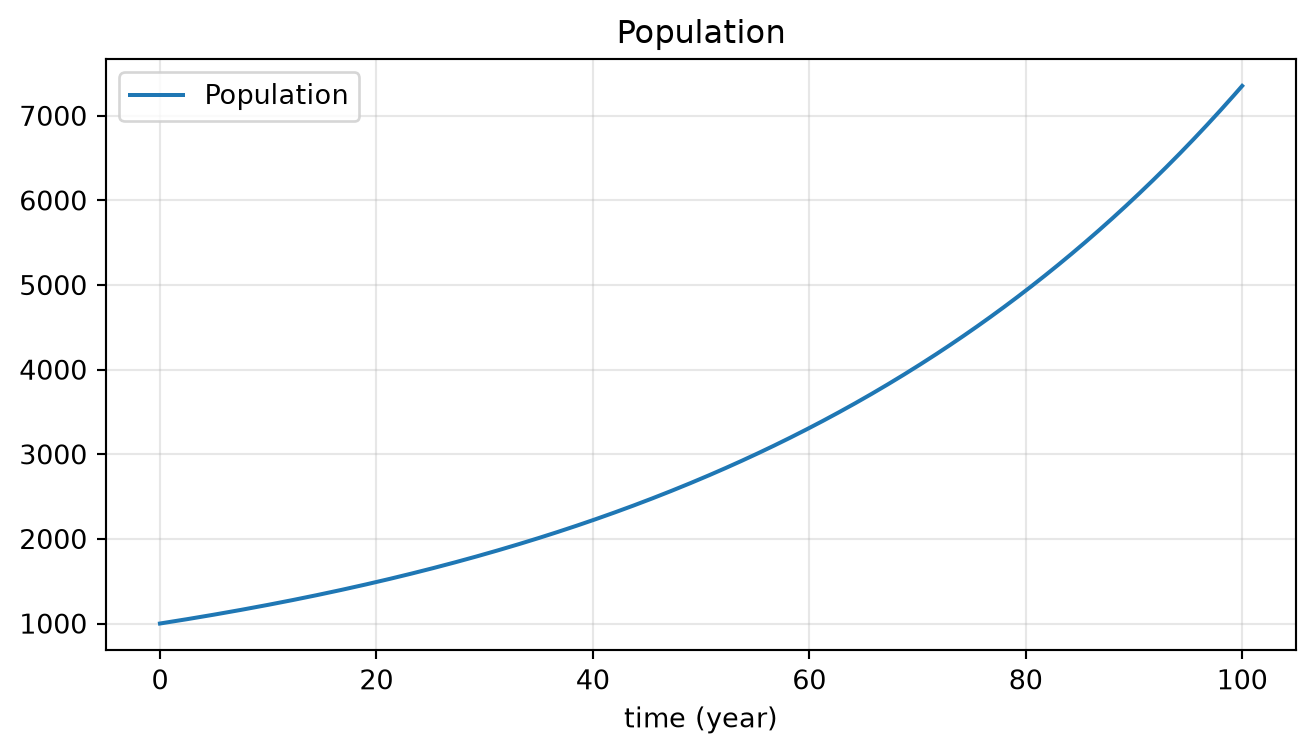

In [9]:
population = lb.Model.from_spec({
    "name": "Population", "timeUnit": "year", "T": 100, "dt": 0.25,
    "stocks": [{"id": "p", "name": "Population", "init": "1000", "x": 0, "y": 0}],
    "flows": [
        {"id": "b", "name": "Births", "to": "p", "eq": "Population * Birth_fraction", "x": 0, "y": 0},
        {"id": "d", "name": "Deaths", "from": "p", "eq": "Population * Death_fraction", "x": 0, "y": 0},
    ],
    "vars": [
        {"id": "bf", "name": "Birth fraction", "eq": "0.03", "x": 0, "y": 0},
        {"id": "df", "name": "Death fraction", "eq": "0.01", "x": 0, "y": 0},
    ],
})
pop = population.run()
population.plot(pop)
print(f"Population after 100 years: {pop['Population'].iloc[-1]:,.0f} (net growth 2% a year doubles it about every 35 years)")

## Where next

- Back in the app: the [Stocks, flows and accumulation](https://waelrash1.github.io/loopbricks/#/learn/stocks-flows) and [Oscillation](https://waelrash1.github.io/loopbricks/#/learn/oscillation) modules teach the ideas behind this notebook, with diagrams and more exercises.
- `help(lb.Model.run)` lists every option. Every molecule takes its constants as keyword arguments; `model.params` lists them and `model.presets` the named scenarios.